# Chest X-Ray Classification: Healthy vs Pneumonia

This notebook trains and compares a custom CNN and MobileNetV3Small using the Kaggle Chest X-Ray Pneumonia dataset.

In [2]:
from google.colab import files
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

In [3]:
print("TensorFlow version:", tf.__version__)

uploaded = files.upload()

os.makedirs("/root/.kaggle", exist_ok=True)

if "kaggle.json" in uploaded:
    shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
else:
    raise FileNotFoundError("kaggle.json was not uploaded. Please upload your Kaggle API file.")

os.chmod("/root/.kaggle/kaggle.json", 0o600)
print("Kaggle API configured successfully.")

!pip install -q kaggle

TensorFlow version: 2.20.0


Saving kaggle.json to kaggle.json
Kaggle API configured successfully.


In [4]:
DATASET_ZIP = "chest-xray-pneumonia.zip"
DATA_DIR = "chest_xray_data"

if not os.path.exists(DATA_DIR):
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
    !unzip -q chest-xray-pneumonia.zip -d chest_xray_data

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:42<00:00, 58.5MB/s]



In [5]:
BASE_DIR = "chest_xray_data/chest_xray"

train_dir = os.path.join(BASE_DIR, "train")
val_dir = os.path.join(BASE_DIR, "val")
test_dir = os.path.join(BASE_DIR, "test")

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
EPOCHS = 10

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


## Healthy vs Pneumonia Images Directly from the Dataset

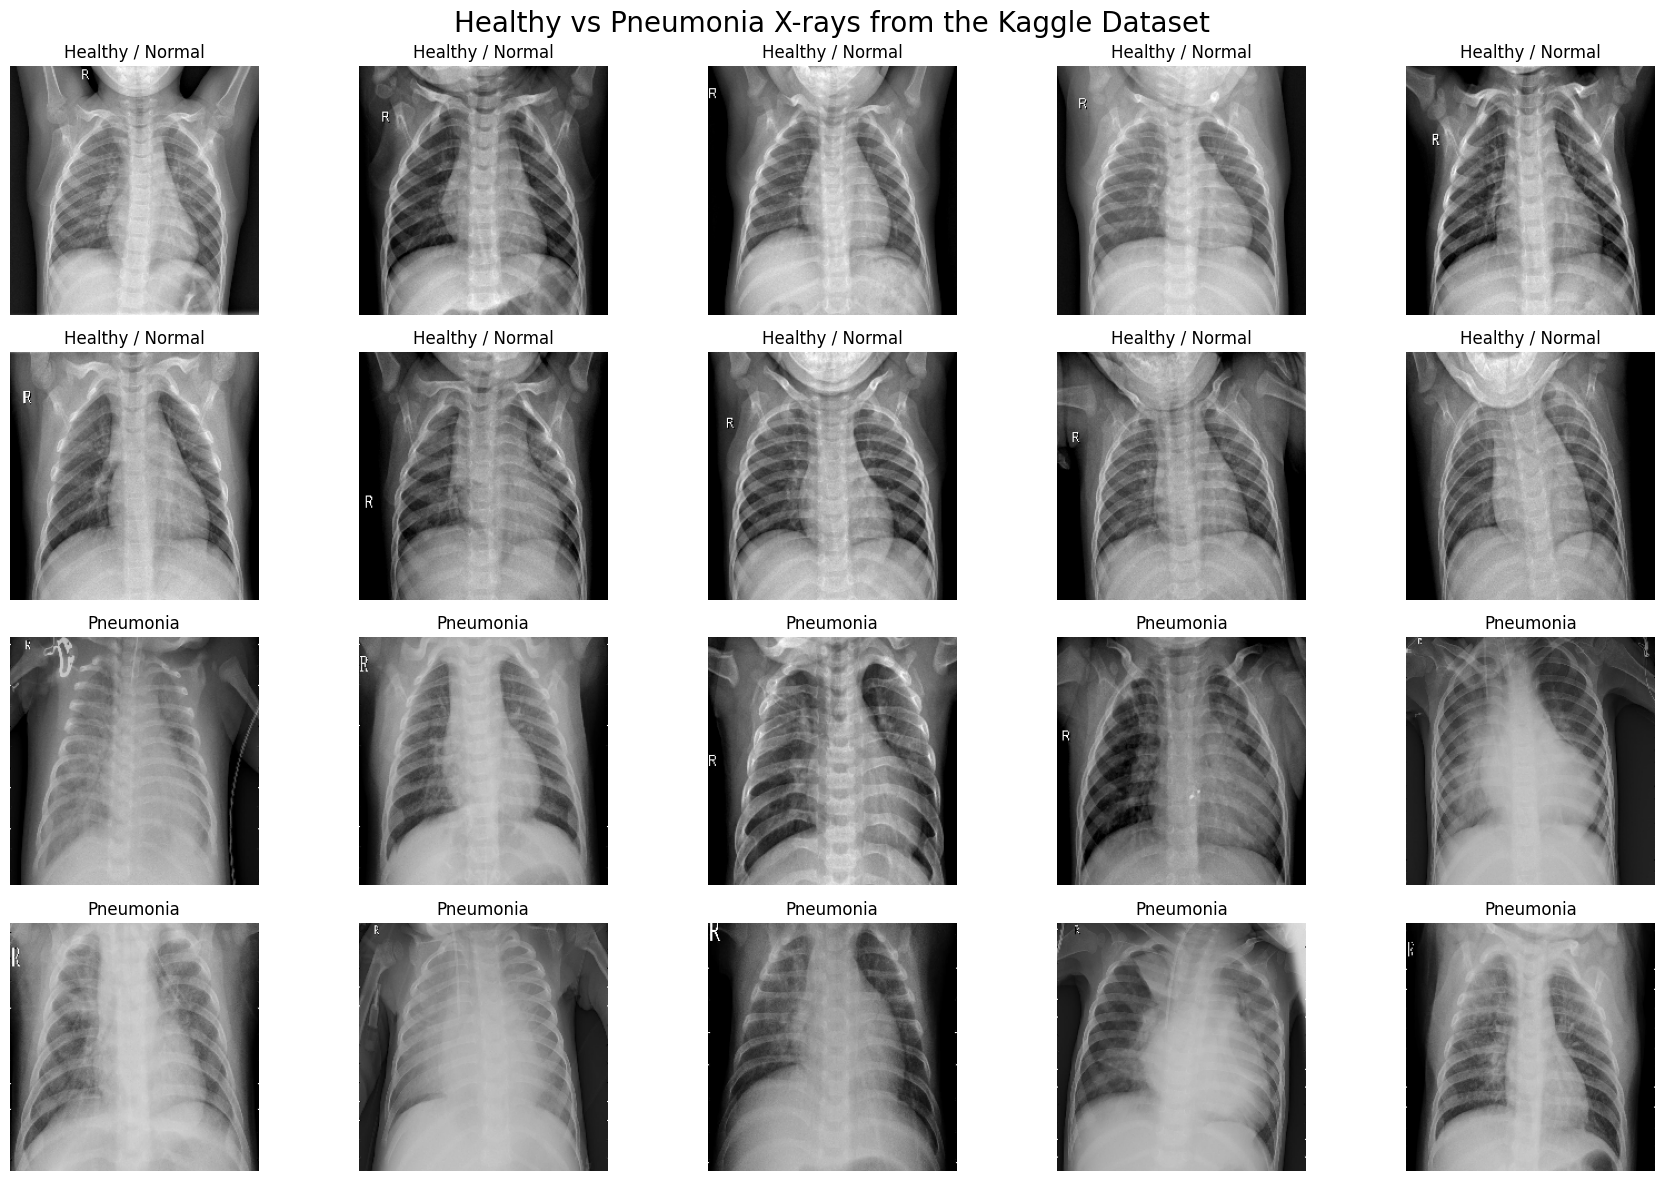

In [7]:
normal_paths = []
pneumonia_paths = []

normal_dir = os.path.join(train_dir, "NORMAL")
pneumonia_dir = os.path.join(train_dir, "PNEUMONIA")

normal_files = [
    os.path.join(normal_dir, f)
    for f in sorted(os.listdir(normal_dir))
    if f.lower().endswith((".jpeg", ".jpg", ".png"))
]

pneumonia_files = [
    os.path.join(pneumonia_dir, f)
    for f in sorted(os.listdir(pneumonia_dir))
    if f.lower().endswith((".jpeg", ".jpg", ".png"))
]

normal_paths = normal_files[:10]
pneumonia_paths = pneumonia_files[:10]

plt.figure(figsize=(18, 12))

for i, path in enumerate(normal_paths):
    image = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    plt.subplot(4, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title("Healthy / Normal")
    plt.axis("off")

for i, path in enumerate(pneumonia_paths):
    image = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    plt.subplot(4, 5, i + 11)
    plt.imshow(image, cmap="gray")
    plt.title("Pneumonia")
    plt.axis("off")

plt.suptitle("Healthy vs Pneumonia X-rays from the Kaggle Dataset", fontsize=20)
plt.tight_layout()
plt.show()

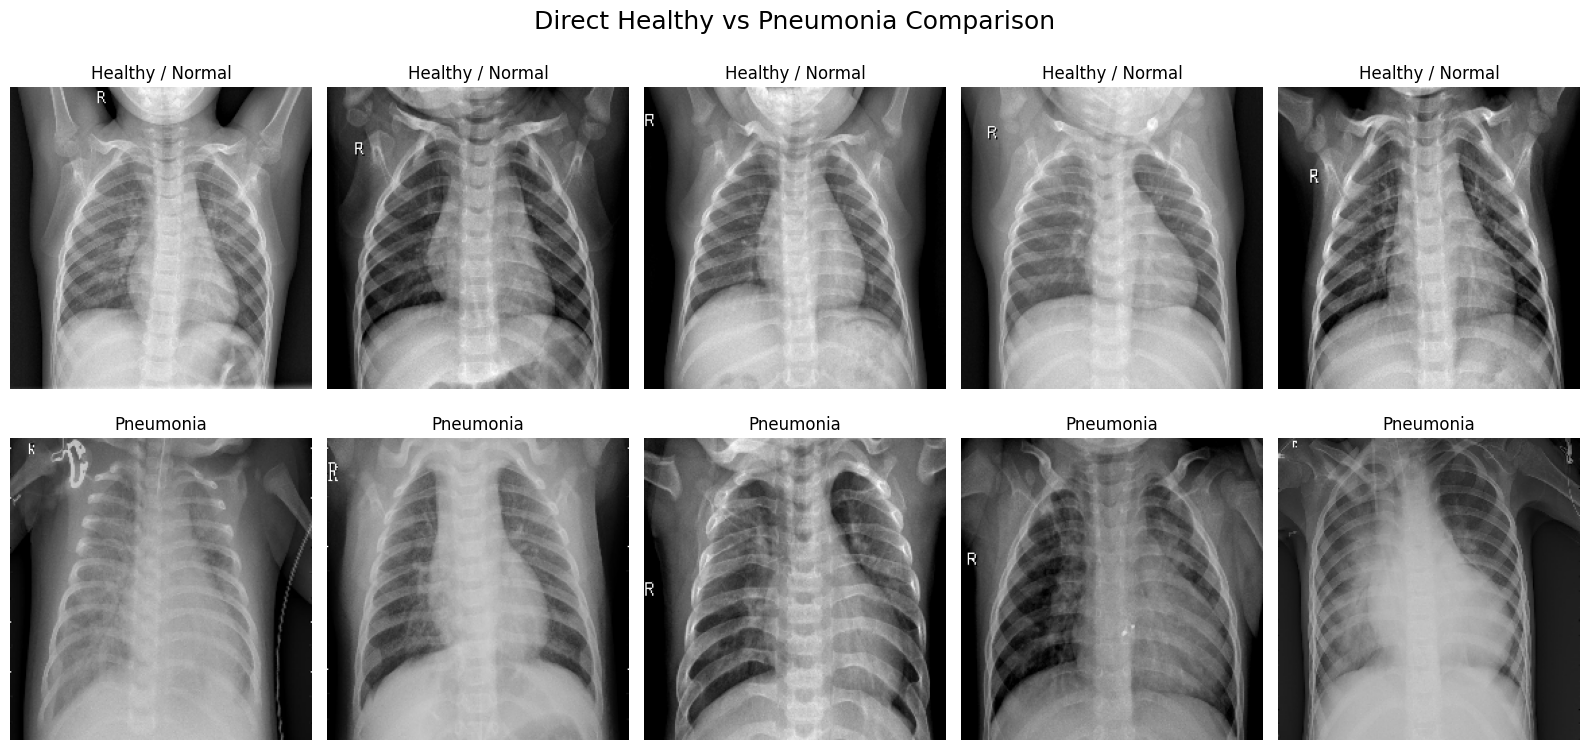

In [8]:
plt.figure(figsize=(16, 8))

for i in range(5):
    normal_image = tf.keras.utils.load_img(
        normal_paths[i],
        target_size=IMG_SIZE
    )

    pneumonia_image = tf.keras.utils.load_img(
        pneumonia_paths[i],
        target_size=IMG_SIZE
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(normal_image, cmap="gray")
    plt.title("Healthy / Normal")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(pneumonia_image, cmap="gray")
    plt.title("Pneumonia")
    plt.axis("off")

plt.suptitle("Direct Healthy vs Pneumonia Comparison", fontsize=18)
plt.tight_layout()
plt.show()

## Custom CNN

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
 21/163 ━━━━━━━━━━━━━━━━━━━━ 14:00 6s/step - accuracy: 0.7459 - auc: 0.8125 - loss: 0.4919 - precision: 0.8484 - recall: 0.7891

## MobileNetV3Small Transfer Learning

In [ ]:
base_model = MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

transfer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

transfer_model.summary()

In [ ]:
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

## Training Accuracy and Loss

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="CNN Training")
plt.plot(cnn_history.history["val_accuracy"], label="CNN Validation")
plt.plot(transfer_history.history["accuracy"], label="MobileNetV3 Training")
plt.plot(transfer_history.history["val_accuracy"], label="MobileNetV3 Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="CNN Training")
plt.plot(cnn_history.history["val_loss"], label="CNN Validation")
plt.plot(transfer_history.history["loss"], label="MobileNetV3 Training")
plt.plot(transfer_history.history["val_loss"], label="MobileNetV3 Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Test Set Evaluation

In [ ]:
cnn_results = cnn_model.evaluate(test_ds, return_dict=True)
transfer_results = transfer_model.evaluate(test_ds, return_dict=True)

print("CNN Test Results")
for metric, value in cnn_results.items():
    print(f"{metric}: {value:.4f}")

print()
print("MobileNetV3Small Test Results")
for metric, value in transfer_results.items():
    print(f"{metric}: {value:.4f}")

In [ ]:
y_true = np.concatenate([
    labels.numpy().astype(int).ravel()
    for _, labels in test_ds
])

cnn_probabilities = cnn_model.predict(test_ds).ravel()
transfer_probabilities = transfer_model.predict(test_ds).ravel()

cnn_predictions = (cnn_probabilities >= 0.5).astype(int)
transfer_predictions = (transfer_probabilities >= 0.5).astype(int)

print("CNN Classification Report")
print(
    classification_report(
        y_true,
        cnn_predictions,
        target_names=class_names
    )
)

print("MobileNetV3Small Classification Report")
print(
    classification_report(
        y_true,
        transfer_predictions,
        target_names=class_names
    )
)

## Confusion Matrices

In [ ]:
cnn_cm = confusion_matrix(y_true, cnn_predictions)
transfer_cm = confusion_matrix(y_true, transfer_predictions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    cnn_cm,
    display_labels=class_names
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("CNN Confusion Matrix")

ConfusionMatrixDisplay(
    transfer_cm,
    display_labels=class_names
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("MobileNetV3Small Confusion Matrix")

plt.tight_layout()
plt.show()

## ROC Curves

In [ ]:
cnn_fpr, cnn_tpr, _ = roc_curve(y_true, cnn_probabilities)
transfer_fpr, transfer_tpr, _ = roc_curve(y_true, transfer_probabilities)

cnn_auc = auc(cnn_fpr, cnn_tpr)
transfer_auc = auc(transfer_fpr, transfer_tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    label=f"CNN AUC = {cnn_auc:.4f}"
)

plt.plot(
    transfer_fpr,
    transfer_tpr,
    label=f"MobileNetV3Small AUC = {transfer_auc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## Actual vs Predicted X-rays

In [ ]:
test_images = []
test_labels = []

for images, labels in test_ds:
    for image, label in zip(images, labels):
        test_images.append(image.numpy())
        test_labels.append(int(label.numpy()))

test_images = np.array(test_images)
test_labels = np.array(test_labels)

sample_indices = np.random.choice(
    len(test_images),
    size=min(12, len(test_images)),
    replace=False
)

plt.figure(figsize=(16, 10))

for plot_index, sample_index in enumerate(sample_indices):
    image = test_images[sample_index]
    actual = class_names[test_labels[sample_index]]
    predicted = class_names[transfer_predictions[sample_index]]

    plt.subplot(3, 4, plot_index + 1)
    plt.imshow(image.astype("uint8"))
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.suptitle("Actual vs Predicted X-rays - MobileNetV3Small", fontsize=18)
plt.tight_layout()
plt.show()

## Misclassified X-rays

In [ ]:
misclassified_indices = np.where(
    transfer_predictions != y_true
)[0]

print("Number of misclassified test images:", len(misclassified_indices))

display_count = min(12, len(misclassified_indices))

if display_count > 0:
    plt.figure(figsize=(16, 10))

    for i in range(display_count):
        index = misclassified_indices[i]

        plt.subplot(3, 4, i + 1)
        plt.imshow(test_images[index].astype("uint8"))
        plt.title(
            f"Actual: {class_names[y_true[index]]}\n"
            f"Predicted: {class_names[transfer_predictions[index]]}"
        )
        plt.axis("off")

    plt.suptitle("Misclassified X-rays - MobileNetV3Small", fontsize=18)
    plt.tight_layout()
    plt.show()

## Final Model Comparison

In [ ]:
metrics = [
    "accuracy",
    "precision",
    "recall",
    "auc"
]

print(f"{'Metric':<12} {'CNN':>12} {'MobileNetV3':>16}")
print("-" * 42)

for metric in metrics:
    print(
        f"{metric:<12} "
        f"{cnn_results[metric]:>12.4f} "
        f"{transfer_results[metric]:>16.4f}"
    )

## Notes

The healthy and pneumonia images shown in this notebook are loaded directly from the Kaggle dataset. The models are intended for educational and research use and are not a substitute for clinical diagnosis.